# Step 3: overview of the data (annotated version)

Before any analysis we need to know three things about the dataset:

1. **How big is it?** Number of cells, genes and donors (embryos).
2. **Does the matrix hold raw counts?** Our definition of "expressed" (at least 1 UMI) and the DESeq2 tests in
   step 07 both need raw counts. If the authors had stored normalised or log values, both would be wrong.
3. **How are age and 10x kit spread across donors?** This decides how we group ages and why the kit matters.

We use the authors' quality-controlled cells and labels, so no cells are removed here.

Output: `results/figures/03_data_overview.png`

*The outputs shown are from the run of 13 November 2026 on the full dataset. Running the notebook again
overwrites them with identical values.*

## Setup

**What this cell does**

- The first lines are the same in every notebook: if we are inside `notebooks/`, move up to the repository
  root so `config.yaml` and `data/` are found. Then let Python import from `src/`.
- **matplotlib** draws the figure and **numpy** does the array maths.
- From our own `common.py`:
  - `B`: the dataset settings from `config.yaml`, used here for the name of the gene symbol column
  - `GENES`: `["LIN28A", "TTYH1", "NES"]`
  - `KIT_COLORS`: blue for v2, orange for v3
  - `open_braun`, `cell_table`, `save`: open the h5ad, build the per-cell table, save the figure

In [1]:
# The notebooks live in notebooks/. Move to the repository root so config.yaml, data/ and results/
# are found, and make src/common.py importable.
import os
import sys

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

import matplotlib.pyplot as plt
import numpy as np

from common import B, GENES, KIT_COLORS, cell_table, open_braun, save

## Load the data

**What this cell does**

- `open_braun()` opens the h5ad file without loading the count matrix into memory (backed mode). We can still
  ask for its size and read parts of it.
- `cell_table(adata)` builds the per-cell table: cell class, cluster, region, kit, donor, age, total UMIs and
  age bin.
- The print line:
  - `adata.n_obs` is the number of cells (rows of the matrix), `adata.n_vars` the number of genes (columns)
  - `cells['donor'].nunique()` counts the distinct donors
  - `:,` in the f-string adds thousands separators, so 1665937 prints as 1,665,937

In [2]:
adata = open_braun()
cells = cell_table(adata)
print(f"{adata.n_obs:,} cells, {adata.n_vars:,} genes, {cells['donor'].nunique()} donors")

1,665,937 cells, 59,459 genes, 26 donors


**Reading the output:** 1.67 million cells from 26 embryos and fetuses, with 59,459 genes measured. The
count matrix would need far more memory than a laptop has if it were loaded whole (most values are zero, but
even the non-zero ones fill many GB). That is why every step reads it in blocks of cells.

## Raw counts and the three genes

**Why this matters:** a raw UMI count is the number of RNA
molecules of a gene caught in a cell. It is always a whole number (0, 1, 2, ...). Normalised data (CPM, log)
has decimals. "Expressed = at least 1 UMI" only means "at least one molecule" on raw counts. DESeq2 also only
accepts raw counts.

**What this cell does**

Check 1, raw counts:
- `first = adata.X[:2000]` reads the first 2,000 cells. A small sample is enough: the whole matrix is stored
  the same way, so if these are raw counts, all are.
- `first.data % 1 == 0`: `% 1` gives the decimal part of a number (3.0 % 1 = 0, 2.7 % 1 = 0.7). If every stored
  value has decimal part 0, all values are whole numbers. `np.all(...)` is True only if this holds for every
  value.
- `first.sum(axis=1)` adds up each cell's counts across all genes (its row sum). This must equal the authors'
  `total_UMIs` for that cell (the `umis` column of our table). `np.array_equal` checks that all 2,000 match
  exactly. If the matrix were normalised, the row sums would not match the totals.
- Both checks must be True (`and`), so the print shows one True or False.

Check 2, the three genes:
- `symbols` is the column of gene symbols in the gene table.
- `(symbols == g).sum()` counts how many genes carry the symbol `g`. It should be exactly 1. With 0 the gene is
  missing (perhaps stored under another name); with 2 or more we would not know which column to use.

In [3]:
# The definitions "expressed = at least 1 UMI" and the DESeq2 tests both need raw counts, not
# normalised values. Raw counts are whole numbers that add up to the authors' total UMIs per cell.
# Checking the first 2,000 cells is enough to see which kind of matrix is stored.
first = adata.X[:2000]
print("raw counts:", np.all(first.data % 1 == 0) and
      np.array_equal(np.asarray(first.sum(axis=1)).ravel(), cells["umis"].to_numpy()[:2000]))

# Each gene should appear exactly once under its symbol (0 = missing, 2 or more = ambiguous)
symbols = adata.var[B["symbol_col"]]
print("genes found:", {g: int((symbols == g).sum()) for g in GENES})

raw counts: True
genes found: {'LIN28A': 1, 'TTYH1': 1, 'NES': 1}


**Reading the output:** the matrix holds raw counts (whole numbers that add up to the authors' totals),
so our 1-UMI definition and DESeq2 are valid on it. Each of LIN28A, TTYH1 and NES is present exactly once, so
step 04 can read their columns without ambiguity.

## Figure: cells, donors and kit per week

**What this cell does**

- `per_age`: cells counted per age and kit. `.groupby(["age", "chemistry"]).size()` gives the counts in a long
  list; `.unstack(fill_value=0)` turns it into a table with one row per age and one column per kit (0 where an
  age has no cells of that kit).
- `donors`: the number of distinct donors at each age.
- `x = np.arange(len(per_age))`: one bar position per age (0, 1, 2, ...). Using positions instead of the ages
  themselves keeps the bars evenly spaced.
- The stacked bars: the loop draws the v2 bar first, starting at `bottom` = 0, then adds its height to
  `bottom`, so the v3 bar starts where v2 ends. Heights are divided by 1,000 to show thousands of cells.
- `ax.text(...)` writes the donor count just above the top of each bar.
- `ax.set_xticks(x, ...)` labels each bar with its age; `f"{a:g}"` prints 6.0 as 6 and 6.6 as 6.6.
- `save(fig, "03_data_overview")` writes the PNG and shows it here.

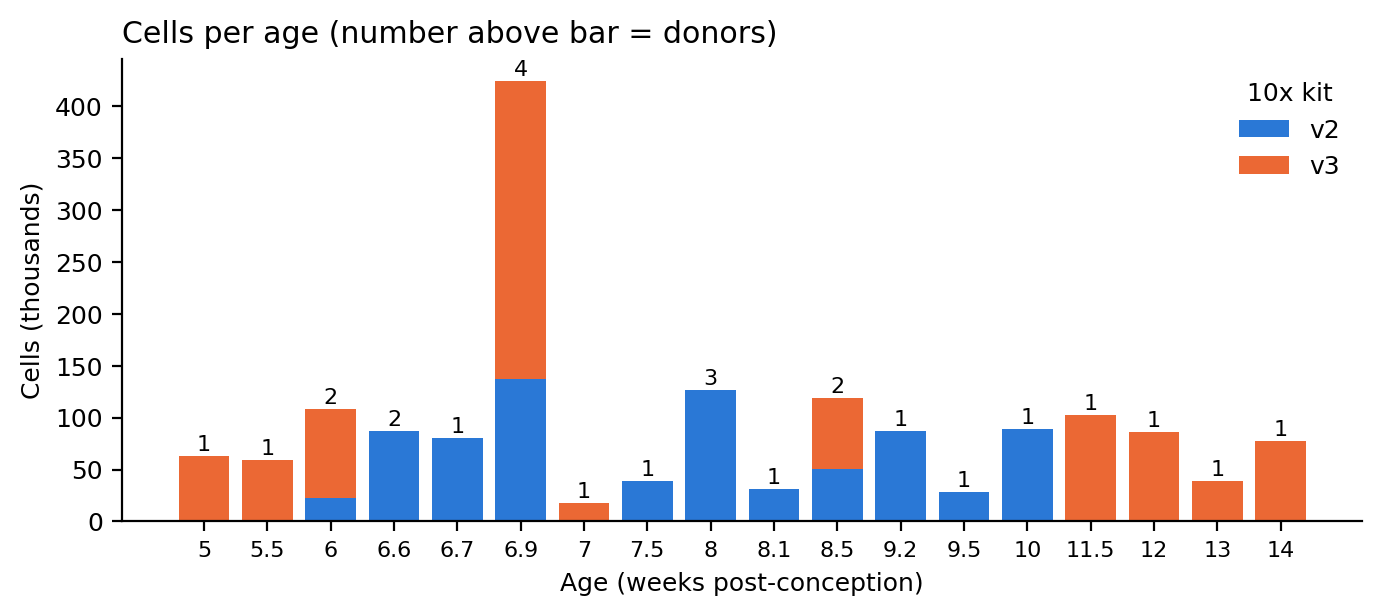

In [4]:
# Stacked bar per week of age: v2 cells at the bottom, v3 on top, number of donors above the bar.
# This shows where both kits overlap in age, which matters for the batch check in step 2.
per_age = cells.groupby(["age", "chemistry"]).size().unstack(fill_value=0)
donors = cells.groupby("age")["donor"].nunique()
x = np.arange(len(per_age))
fig, ax = plt.subplots(figsize=(8, 3))
bottom = np.zeros(len(per_age))
for kit, color in KIT_COLORS.items():
    ax.bar(x, per_age[kit] / 1000, bottom=bottom, color=color, label=kit)
    bottom += per_age[kit] / 1000
for xi, top, n in zip(x, bottom, donors):
    ax.text(xi, top + 5, n, ha="center", fontsize=8)
ax.set_xticks(x, [f"{a:g}" for a in per_age.index], fontsize=8)
ax.set_xlabel("Age (weeks post-conception)")
ax.set_ylabel("Cells (thousands)")
ax.set_title("Cells per age (number above bar = donors)", loc="left")
ax.legend(title="10x kit")
save(fig, "03_data_overview")

**Reading the figure**

- **Ages:** 18 different ages from 5 to 14 weeks post-conception.
- **Donors per age:** most ages have only 1 or 2 donors (6.9 weeks has 4, 8 weeks has 3). One donor per age
  is too few to compare single weeks, which is why the analysis groups ages into three bins:
  - **early (5 to 7 weeks):** 12 donors with both kits, the bin with the best v2 and v3 overlap
  - **mid (7.5 to 9.5 weeks):** 9 donors, almost all v2; v3 only at 8.5 weeks
  - **late (10 to 14 weeks):** 5 donors, all v3 except one v2 donor at 10 weeks
- **Kit and age overlap only partly.** v3 covers the youngest and oldest ages, v2 the middle. If we compared
  ages without thinking about the kit, part of every age difference would really be a kit difference.

## Conclusion of step 03

1. The dataset has 1,665,937 cells, 59,459 genes and 26 donors.
2. The matrix holds raw UMI counts, so "expressed = at least 1 UMI" and DESeq2 are valid.
3. All three genes are present exactly once.
4. Ages are grouped into three bins because single weeks have too few donors.
5. Kit and age are partly linked: early has both kits, mid is mostly v2 and late is mostly v3. This is why
   step 02 measures the kit effect in the early bin and step 07 puts the kit in the stage test.